In [1]:
#@title A HEART DISEASE PREDICTOR USING LOGISTIC REGRESSION MODEL


In [2]:
#@title Background and Goal
print("""
Backgound
The early prognosis of cardiovascular diseases can aid in making decisions on lifestyle changes in high risk patients and in turn reduce the complications.
This research intends to pinpoint the most relevant/risk factors of heart disease as well as predict the overall risk using logistic regression model.

Goal
The goal of this project is to predict whether a patient has heart disease based on the available clinical attributes.

Research Questions
RQ1: Can logistic regression be used to classify and predict patients with heart disease?
RQ2: feature selection guided by correlation analysis improves the predictive performance of Logistic Regression?

""")


Backgound
The early prognosis of cardiovascular diseases can aid in making decisions on lifestyle changes in high risk patients and in turn reduce the complications.
This research intends to pinpoint the most relevant/risk factors of heart disease as well as predict the overall risk using logistic regression model.

Goal
The goal of this project is to predict whether a patient has heart disease based on the available clinical attributes.

Research Questions
RQ1: Can logistic regression be used to classify and predict patients with heart disease?
RQ2: feature selection guided by correlation analysis improves the predictive performance of Logistic Regression?




In [3]:
#@title MetaData: What you need to know about the data

print("""

Column Descriptions:

1. id: (Unique id for each patient)

2. age: (Age of the patient in years)

3. origin: (place of study)

4. sex: (Male/Female)

5. cp: chest pain type
    - Asymptomatic: No chest pain or discomfort.
    - Non-Anginal: Chest pain not typical of heart-related issues; requires further investigation.
    - Atypical Angina: Chest pain with characteristics different from typical heart-related chest pain.
    - Typical Angina: Classic chest pain indicating potential insufficient blood supply to the heart.

6. trestbps:  resting blood pressure (resting blood pressure (in mm Hg on admission to the hospital))
    - The normal resting blood pressure is 120/80 mm Hg.High blood pressure increasing the risk of heart disease and stroke, often asymptomatic, while low blood pressure can lead to dizziness and fainting.

7. chol: (serum cholesterol in mg/dl

    - What is the chol : a fatty substance essential for body function, but elevated levels can contribute to heart disease.

8. fbs: (if fasting blood sugar > 120 mg/dl)

9. restecg: (resting electrocardiographic results)
    - Values: [normal, stt abnormality, lv hypertrophy]

10. thalach: maximum heart rate achieved

11. exang: exercise-induced angina (True/ False)

12. oldpeak: ST depression induced by exercise relative to rest

13. slope: the slope of the peak exercise ST segment

14. ca: number of major vessels (0-3) colored by fluoroscopy

15. thal: [normal; fixed defect; reversible defect]

    - Normal: Within expected or healthy parameters.

    - Reversible Defect: An abnormality that can potentially be corrected or improved.

    - Fixed Defect: An abnormality that is unlikely to change or be corrected.

16. num: the predicted attribute

""")



Column Descriptions:

1. id: (Unique id for each patient)

2. age: (Age of the patient in years)

3. origin: (place of study)

4. sex: (Male/Female)

5. cp: chest pain type
    - Asymptomatic: No chest pain or discomfort.
    - Non-Anginal: Chest pain not typical of heart-related issues; requires further investigation.
    - Atypical Angina: Chest pain with characteristics different from typical heart-related chest pain.
    - Typical Angina: Classic chest pain indicating potential insufficient blood supply to the heart.

6. trestbps:  resting blood pressure (resting blood pressure (in mm Hg on admission to the hospital))
    - The normal resting blood pressure is 120/80 mm Hg.High blood pressure increasing the risk of heart disease and stroke, often asymptomatic, while low blood pressure can lead to dizziness and fainting.

7. chol: (serum cholesterol in mg/dl

    - What is the chol : a fatty substance essential for body function, but elevated levels can contribute to heart disease

In [4]:
# @title Environment Setup and Configuration

import os
import kagglehub
import pandas as pd #for data manipulation, data cleaning, exploration, and structural analysis
import numpy as np  #for numerical computations
import matplotlib.pyplot as plt #for data visuation
from sklearn.linear_model import LogisticRegression #LogisticRegression is not located at the root level of the sklearn library, therefore specify exact submodule where model lives
from sklearn.model_selection import train_test_split   #to spilt data
from sklearn.compose import ColumnTransformer          #allows for multiple column transformation
from sklearn.preprocessing import OneHotEncoder, StandardScaler    #encoding categorical data and normalizing different scales of numerical variables
from sklearn.pipeline import Pipeline                            #provides flow
from sklearn.metrics import log_loss                             #to evaluate accuracy of probability predictions
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    log_loss,
    classification_report,
    roc_curve,
    roc_auc_score
)                                                               #evaluate matrix based on confusion matrix

from sklearn.feature_selection import SelectKBest, f_classif




print("all libraries imported and installed successfully. Happy Coding!")

all libraries imported and installed successfully. Happy Coding!


In [5]:
#@title Data
data_download = kagglehub.dataset_download("redwankarimsony/heart-disease-data")    #download files to folder
print("folder path: ", data_download)
print("files in this folder: ", os.listdir(data_download))                           #view files in the folder
data = pd.read_csv("/kaggle/input/heart-disease-data/heart_disease_uci.csv")
print("Dataset preview")
data.head()

Using Colab cache for faster access to the 'heart-disease-data' dataset.
folder path:  /kaggle/input/heart-disease-data
files in this folder:  ['heart_disease_uci.csv']
Dataset preview


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [6]:
#@title Data Shape and Variables
print ("This data has", data.shape[0], "rows and", data.shape[1], "columns in total")
print("Variables in the dataset include, ", data.columns)

This data has 920 rows and 16 columns in total
Variables in the dataset include,  Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')


In [7]:
#@title Clinical Features for a Heart Disease Diagnosis
print("""Not all variables are correlated to diagnose a heart disease.
It is imperative to select relevant features for analysis and modelling.
All the features are relevant excluding id and dataset.
We are not interested in doing prediction by region.
The goal of this project is to predict whether a patient has heart disease based on the available clinical attributes.
Some variables will be ignored including id and dataset
The most important variables we will use include: """, data[['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs','restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']].columns)
data.drop(columns = ['id', 'dataset'], inplace = True)


Not all variables are correlated to diagnose a heart disease.
It is imperative to select relevant features for analysis and modelling.
All the features are relevant excluding id and dataset.
We are not interested in doing prediction by region.
The goal of this project is to predict whether a patient has heart disease based on the available clinical attributes.
Some variables will be ignored including id and dataset
The most important variables we will use include:  Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')


In [8]:
#@title Data Understanding: Datatype, Duplicates and Missing Values

print("The dataset has ", data.duplicated().sum(), "of duplicates" )
print("This dataset has ", data.isnull().sum().sum(), "of missing values")
data.dtypes

The dataset has  2 of duplicates
This dataset has  1759 of missing values


,0
age,int64
sex,object
cp,object
trestbps,float64
chol,float64
fbs,object
restecg,object
thalch,float64
exang,object
oldpeak,float64


In [9]:
#@title Duplicate Inspection
duplicate_rows = data[data.duplicated(keep = False)]
print("Duplicate Rows :")
duplicate_rows

Duplicate Rows :


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
404,49,Female,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,NaN,NaN,NaN,0
405,49,Female,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,NaN,NaN,NaN,0
859,58,Male,non-anginal,150.0,219.0,False,st-t abnormality,118.0,True,0.0,NaN,NaN,NaN,2
907,58,Male,non-anginal,150.0,219.0,False,st-t abnormality,118.0,True,0.0,NaN,NaN,NaN,2


In [10]:
#@title Drop Duplicates
data.drop_duplicates(inplace = True )  # drops excluding first occurrence
print("After dropping duplicates, the data has ", data.duplicated().sum(), "number of duplicates")

After dropping duplicates, the data has  0 number of duplicates


In [11]:
#@title Missing Values by Columns
data.info()
print("""
From the description it is evident that only
columns age,sex, cp, and num do not have missing values.
Notice ca(missing values = 609) and thal (missing values = 484) have the most missing values.

Blindly filing the missing values can introduce bias, inaccurancies, and invalidities.
We might consider dropping those varibles with alot of missing values.


Imputing missing values with mean, median, or mode depending on:
a. Datatype
b. Distribution
""")

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 0 to 919
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   cp        918 non-null    object 
 3   trestbps  859 non-null    float64
 4   chol      889 non-null    float64
 5   fbs       828 non-null    object 
 6   restecg   916 non-null    object 
 7   thalch    863 non-null    float64
 8   exang     863 non-null    object 
 9   oldpeak   856 non-null    float64
 10  slope     611 non-null    object 
 11  ca        309 non-null    float64
 12  thal      434 non-null    object 
 13  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(7)
memory usage: 107.6+ KB

From the description it is evident that only
columns age,sex, cp, and num do not have missing values.
Notice ca(missing values = 609) and thal (missing values = 484) have the most missing values.

Blindly filing

In [12]:
#@title Dropping Ca and thal columns
data.drop(columns = ["ca", "thal"], inplace = True)


In [13]:
#@title Step 1: Understand unique values towards addressing Cleaning Data
# function that loops through the dataframe and check for unique values in each column

def unique_values_checker(data):
  unique_values  = {}
  for cols in data.columns:
    unique_values[cols] = data[cols].unique()
  return unique_values

unique_values_checker(data)


{'age': array([63, 67, 37, 41, 56, 62, 57, 53, 44, 52, 48, 54, 49, 64, 58, 60, 50,
        66, 43, 40, 69, 59, 42, 55, 61, 65, 71, 51, 46, 45, 39, 68, 47, 34,
        35, 29, 70, 77, 38, 74, 76, 28, 30, 31, 32, 33, 36, 72, 73, 75]),
 'sex': array(['Male', 'Female'], dtype=object),
 'cp': array(['typical angina', 'asymptomatic', 'non-anginal', 'atypical angina'],
       dtype=object),
 'trestbps': array([145., 160., 120., 130., 140., 172., 150., 110., 132., 117., 135.,
        112., 105., 124., 125., 142., 128., 170., 155., 104., 180., 138.,
        108., 134., 122., 115., 118., 100., 200.,  94., 165., 102., 152.,
        101., 126., 174., 148., 178., 158., 192., 129., 144., 123., 136.,
        146., 106., 156., 154., 114., 164.,  98., 190.,  nan, 113.,  92.,
         95.,  80., 185., 116.,   0.,  96., 127.]),
 'chol': array([233., 286., 229., 250., 204., 236., 268., 354., 254., 203., 192.,
        294., 256., 263., 199., 168., 239., 275., 266., 211., 283., 284.,
        224., 206., 219

**Notes**   
Handling missing values and outliers in numerical data: Which comes first?

This is an important question in machine learning preprocessing because the order in which you handle missing values and outliers can affect the quality of your imputed data.

The short answer is:

Generally, investigate and handle outliers before imputing missing values, but do not automatically remove all outliers. First understand the distribution, determine whether extreme values are genuine or errors, and then choose an appropriate imputation method.
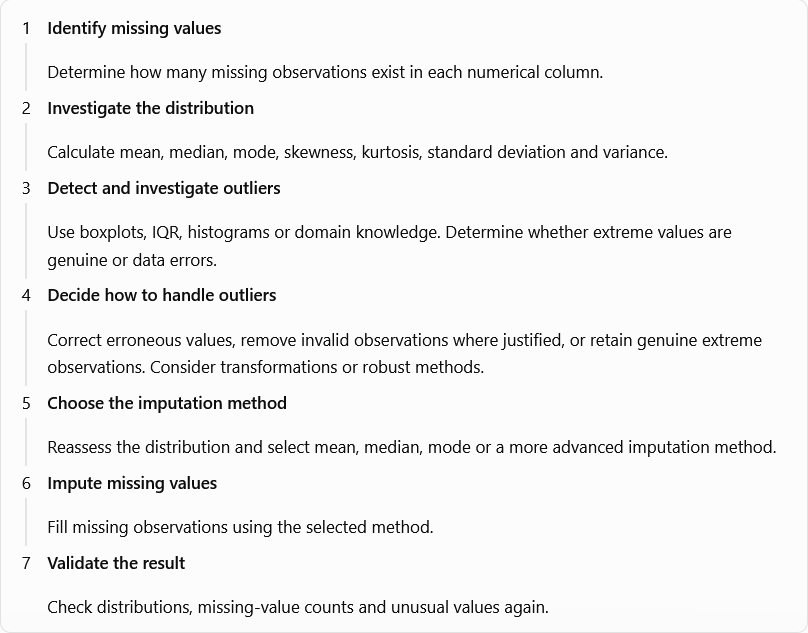

One important qualification: this is a general workflow, not an absolute rule. Sometimes you need to impute first to enable a particular outlier-detection algorithm. In that situation, use a temporary, appropriate imputation method and revisit the results


From the results the following needs to be done:
i. Standardize formating in of numerical variables to 2 decimal place.
     (There are inconsistencies)
ii.Replace missing values using appropriate statistical estimates
      (For columns: Chol, trestbps, fbs, restecg,exang)


Numerical columns
                    trestbps      chol  thalch  oldpeak
Mean                  132.14    199.11  137.54     0.88
Median                130.00    223.00  140.00     0.50
Mode                  120.00      0.00  150.00     0.00
Kurtosis                2.97      0.06   -0.48     1.12
Skewness                0.21     -0.61   -0.21     1.04
Variance              363.42  12285.76  672.70     1.19
Standard Deviation     19.06    110.84   25.94     1.09
Minimum                 0.00      0.00   60.00    -2.60
Maximum               200.00    603.00  202.00     6.20

All the variables are slightly skewed.
This suggest presence of outliers
The zero and negative values need further inspection
Visualize distrib

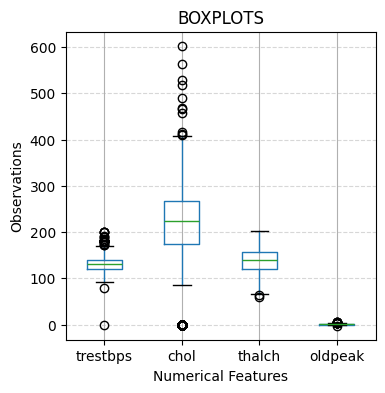


Results show presence of outliers
Missig values Successfully Imputed. Total missing values is: 0


In [14]:
#@title Data Cleaning Actions: Numerical Variables
print("""
From the results the following needs to be done:
i. Standardize formating in of numerical variables to 2 decimal place.
     (There are inconsistencies)
ii.Replace missing values using appropriate statistical estimates
      (For columns: Chol, trestbps, fbs, restecg,exang)

""")

#loop through all floating-point columns to one dp
cols = data[["trestbps", "chol", "thalch", "oldpeak"]]
for col in cols:
  data[col] = round(data[col],2)

#Data distribution using descriptive statistics
print("Numerical columns")

#loop through the columns, calculate and return to get mean, median, mode, kurtosis, and skewness

description = {}

for col in cols:
    description[col] = {
        "Mean": round(float(data[col].mean()), 2),
        "Median": round(float(data[col].median()), 2),
        "Mode": round(float(data[col].mode().iloc[0]), 2),
        "Kurtosis": round(float(data[col].kurtosis()), 2),
        "Skewness": round(float(data[col].skew()), 2),
        "Variance": round(float(data[col].var()), 2),
        "Standard Deviation": round(float(data[col].std()), 2),
        "Minimum" : round(float(data[col].min()),2),
        "Maximum" : round(float(data[col].max()),2)
    }

# Convert dictionary to DataFrame and transpose
description_df = pd.DataFrame(description)

print(description_df)

print("""
All the variables are slightly skewed.
This suggest presence of outliers
The zero and negative values need further inspection
Visualize distribution to confirm skewness
It is important to understand which estimate to use for imputing missing values""")

#visualization
plt.figure(figsize = (4,4))
cols.boxplot()
plt.title("BOXPLOTS")
plt.ylabel("Observations")
plt.xlabel("Numerical Features")
plt.xticks(rotation = 0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

print("\nResults show presence of outliers")

Variable = ["trestbps", "chol", "thal", "oldpeak"]
distribution = ["Slight Positive Skewed", "Moderate Negative Skewed", "Slight Negative Skewed", "Positive Skewed"]
Estimate_impute = ["Mean", "Median", "Mean","Median"]

proposed_imputation = pd.DataFrame({
    "Variable": Variable,
    "Distribution": distribution,
    "Estimate_impute": Estimate_impute
})

proposed_imputation

#Fill mising Values using Proposed Imputations
data['trestbps'] = data['trestbps'].fillna(data['trestbps'].mean())
data['oldpeak'] = data['oldpeak'].fillna(data['oldpeak'].median())
data['chol'] = data['chol'].fillna(data['chol'].median())
data['thalch'] = data['thalch'].fillna(data['thalch'].mean())

# Display missing values per column
print("Missig values Successfully Imputed. Total missing values is:", data[col].isna().sum().sum())


In [15]:
#@title Data Cleaning Actions: Categorical Variables

print("Categorical columns")
for cols in ['fbs', 'restecg', 'exang', 'slope']:
    print(data[cols].value_counts(dropna=False))

print("""
Check the frequency counts of unique values to inform on using mode to impute missing values.
From the results, it is reasonable to impute missing values of fbs, restecg, and exang with mode.
Missing values in slope are many, consider introducing a category "missing"
""")
# Mode imputation
data['fbs'] = data['fbs'].fillna(data['fbs'].mode()[0])
data['restecg'] = data['restecg'].fillna(data['restecg'].mode()[0])
data['exang'] = data['exang'].fillna(data['exang'].mode()[0])
data['slope'] = data['slope'].fillna('Missing')

# Display missing values per column
print("\nMissig values Successfully Imputed. Total missing values is:", data[col].isna().sum().sum())

Categorical columns
fbs
False    690
True     138
NaN       90
Name: count, dtype: int64
restecg
normal              550
lv hypertrophy      188
st-t abnormality    178
NaN                   2
Name: count, dtype: int64
exang
False    527
True     336
NaN       55
Name: count, dtype: int64
slope
flat           345
NaN            307
upsloping      203
downsloping     63
Name: count, dtype: int64

Check the frequency counts of unique values to inform on using mode to impute missing values.
From the results, it is reasonable to impute missing values of fbs, restecg, and exang with mode.
Missing values in slope are many, consider introducing a category "missing"


Missig values Successfully Imputed. Total missing values is: 0


/tmp/ipykernel_810/390492448.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['fbs'] = data['fbs'].fillna(data['fbs'].mode()[0])
/tmp/ipykernel_810/390492448.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['exang'] = data['exang'].fillna(data['exang'].mode()[0])


Accuracy: 0.8297101449275363
Log Loss: 0.42259937581977497
Confusion Matrix:
 [[100  23]
 [ 24 129]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.81      0.81       123
           1       0.85      0.84      0.85       153

    accuracy                           0.83       276
   macro avg       0.83      0.83      0.83       276
weighted avg       0.83      0.83      0.83       276

ROC-AUC Score: 0.8854


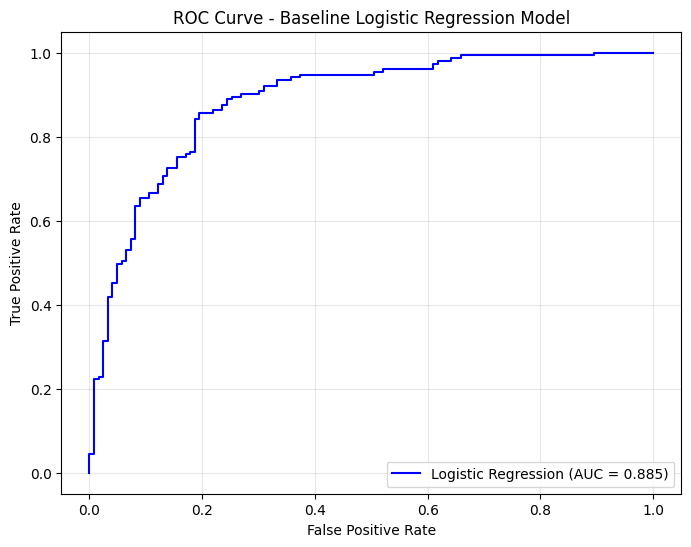

In [16]:
#@title Baseline Model: No Feature Selection and Correlational Analysis
#make a copy of the data for fitting model
data_copy1 = data.copy()
data_copy1.columns

#convert multiclass to binary class (to answer objective of research question)
data_copy1['num'] = (data_copy1['num'] > 0).astype(int)
#isolate independent and dependent varibles
X = data_copy1.drop('num',axis = 1)
y = data_copy1['num']

#Split data into 70% train and 30% test
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42, stratify=y)

#transform data: encode and standardize scale

numeric_cols = ["age", "chol", "oldpeak", "trestbps", "thalch"]
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope"]

#pipeline to transform data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(
            drop='if_binary',
            handle_unknown='ignore'
        ), categorical_cols)
    ]
)
#initial model and fit into data

baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# fit model
baseline_model.fit(X_train, y_train)

#Evaluate model
# Predicted probabilities
y_pred = baseline_model.predict(X_test)
y_pred_proba = baseline_model.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Log Loss:", log_loss(y_test, y_pred_proba))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n",
      classification_report(y_test, y_pred))

#ROC and AUC curves
# Positive predicted probabilities for the positive class
y_pred_proba_positive = y_pred_proba[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba_positive)

print("ROC-AUC Score:", round(roc_auc, 4))

# Calculate False Positive Rate and True Positive Rate
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_positive)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, color='blue',
         label=f'Logistic Regression (AUC = {roc_auc:.3f})')


plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Baseline Logistic Regression Model')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()



In [17]:
#@title Interpretations
print("""
Baseline Logistic Regression Model Performance

The baseline Logistic Regression model achieved an accuracy of 82.97% and a Log Loss of 0.4226 on the test dataset.
The model obtained a macro-averaged F1-score of 0.83.
Indicating relatively consistent classification performance across the two target classes.

The confusion matrix showed that the model correctly classified 100 observations belonging to class 0
And 129 observations belonging to class 1.
However, 23 false positives and 24 false negatives were recorded.
The recall for the positive class was 84%, suggesting that the model correctly identified most of the observations associated with heart disease.

Overall, the baseline model demonstrated promising classification performance.
And provides a reference point against which subsequent feature-selection models can be evaluated.

Furthermore, the model achieved an ROC-AUC score of 0.8854.
Indicating good discriminatory ability in distinguishing between individuals with heart disease and those without the condition.
This suggests that the model has a strong ability to differentiate between the two classes across different classification thresholds.
The ROC-AUC result suggest of the model's predictive performance beyond the accuracy and classification metrics.

Overall, the baseline Logistic Regression model demonstrated promising classification and discriminatory performance.
 These results provide a benchmark against which subsequent feature-selection models can be evaluated:
  to determine whether feature selection improves the model's predictive performance
""")


Baseline Logistic Regression Model Performance

The baseline Logistic Regression model achieved an accuracy of 82.97% and a Log Loss of 0.4226 on the test dataset.
The model obtained a macro-averaged F1-score of 0.83.
Indicating relatively consistent classification performance across the two target classes.

The confusion matrix showed that the model correctly classified 100 observations belonging to class 0
And 129 observations belonging to class 1.
However, 23 false positives and 24 false negatives were recorded.
The recall for the positive class was 84%, suggesting that the model correctly identified most of the observations associated with heart disease.

Overall, the baseline model demonstrated promising classification performance.
And provides a reference point against which subsequent feature-selection models can be evaluated.

Furthermore, the model achieved an ROC-AUC score of 0.8854.
Indicating good discriminatory ability in distinguishing between individuals with heart dise

In [18]:

#@title Understanding Relationship between Variables: Correlation and multicollinearity analysis
print("""
Correlation Analysis depending on data types.

    - Pearson correlation for continuous variables with approximately linear relationships.

    - Spearman correlation for monotonic relationships or ordinal variables.

    - Cramér's V for categorical variables.

    - Point-biserial correlation for a continuous variable against a binary outcome

""")

# Point-Biserial Correlation Analysis

import pandas as pd
from scipy.stats import pointbiserialr

# Numerical predictors
numeric_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]

# Store correlation results
results = []

for col in numeric_cols:

    correlation, p_value = pointbiserialr(
        y_train,
        X_train[col]
    )

    results.append({
        "Feature": col,
        "Correlation": correlation,
        "P-value": p_value
    })

# Create results DataFrame
point_biserial_results = pd.DataFrame(results)

# Sort by absolute correlation strength
point_biserial_results["Absolute Correlation"] = (
    point_biserial_results["Correlation"].abs()
)

point_biserial_results = point_biserial_results.sort_values(
    by="Absolute Correlation",
    ascending=False
)

display(point_biserial_results.round(4))


# Cramér's V for categorical predictors against target

import numpy as np
from scipy.stats import chi2_contingency

def cramers_v(x, y):

    confusion_matrix = pd.crosstab(x, y)

    chi2 = chi2_contingency(confusion_matrix)[0]

    n = confusion_matrix.sum().sum()

    r, k = confusion_matrix.shape

    return np.sqrt(chi2 / (n * min(k - 1, r - 1)))


categorical_cols = [
    "sex", "cp", "fbs", "restecg", "exang", "slope"
]

categorical_results = []

for col in categorical_cols:

    association = cramers_v(X_train[col], y_train)

    categorical_results.append({
        "Feature": col,
        "Cramer's V": association
    })

cramers_results = pd.DataFrame(categorical_results)

cramers_results = cramers_results.sort_values(
    by="Cramer's V",
    ascending=False
)

display(cramers_results.round(4))


print("""
From the results; consider:

Retain Numerical predictors

    thalch (-0.4034)

    oldpeak (0.3622)

    age (0.2993)

    chol (-0.2195)

Retain Categorical predictors

    cp (0.5237)

    exang (0.4328)

    slope (0.3806)

    sex (0.2925)

Consider removing

    trestbps (0.1416)

    restecg (0.1457)

    fbs (0.0703)


""")


Correlation Analysis depending on data types.

    - Pearson correlation for continuous variables with approximately linear relationships.

    - Spearman correlation for monotonic relationships or ordinal variables.

    - Cramér's V for categorical variables.

    - Point-biserial correlation for a continuous variable against a binary outcome




,Feature,Correlation,P-value,Absolute Correlation
3,thalch,-0.4034,0.0000,0.4034
4,oldpeak,0.3622,0.0000,0.3622
0,age,0.2993,0.0000,0.2993
2,chol,-0.2195,0.0000,0.2195
1,trestbps,0.1416,0.0003,0.1416


,Feature,Cramer's V
1,cp,0.5237
4,exang,0.4328
5,slope,0.3806
0,sex,0.2925
3,restecg,0.1457
2,fbs,0.0703



From the results; consider:

Retain Numerical predictors

    thalch (-0.4034)

    oldpeak (0.3622)

    age (0.2993)

    chol (-0.2195)

Retain Categorical predictors

    cp (0.5237)

    exang (0.4328)

    slope (0.3806)

    sex (0.2925)

Consider removing

    trestbps (0.1416)

    restecg (0.1457)

    fbs (0.0703)





Accuracy: 0.8260869565217391
Log Loss: 0.4200289161444299
Confusion Matrix:
 [[ 99  24]
 [ 24 129]]

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.80      0.80       123
           1       0.84      0.84      0.84       153

    accuracy                           0.83       276
   macro avg       0.82      0.82      0.82       276
weighted avg       0.83      0.83      0.83       276

ROC-AUC Score: 0.8861


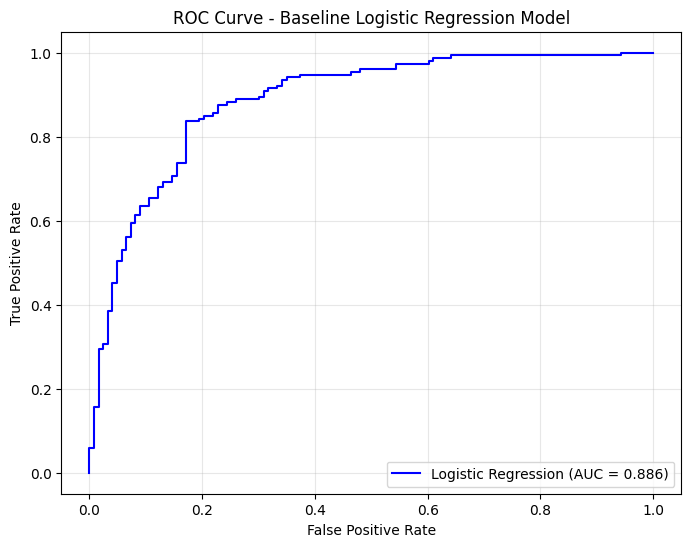


The model achieved an accuracy of approximately 82.61%, which represents a slight decrease compared to the baseline model's accuracy of 82.97%.

The confusion matrix indicates that:

    99 instances of Class 0 were correctly classified.

    129 instances of Class 1 were correctly classified.

    24 instances of Class 0 were incorrectly classified as Class 1.

    24 instances of Class 1 were incorrectly classified as Class 0.

The classification report shows that Class 0 achieved a precision of 0.80 and recall of 0.80, while Class 1 achieved a precision of 0.84 and recall of 0.84.

Compared to the baseline model, there is a slight reduction in precision, recall, and F1-score for both classes.

However, the Log Loss decreased from 0.4226 to 0.4200, indicating a slight improvement in the quality of the predicted probabilities.

Similarly, the ROC-AUC increased marginally from 0.8854 to 0.8861. This suggests that the feature-selected model has a slightly better ability to distinguish 

In [19]:
#@title Model Improvement: Based on Feature Selection Guided by correlational Analysis
data_copy2 = data.drop(columns = ["trestbps", "fbs", "restecg"])
data_copy2.columns


#convert multiclass to binary class (to answer objective of research question)
data_copy2['num'] = (data_copy2['num'] > 0).astype(int)
#isolate independent and dependent varibles
X = data_copy2.drop('num',axis = 1)
y = data_copy2['num']

#Split data into 70% train and 30% test
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42, stratify=y)

#transform data: encode and standardize scale

numeric_cols = ["age", "chol", "oldpeak", "thalch"]
categorical_cols = ["sex", "cp", "exang", "slope"]

#pipeline to transform data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(
            drop='if_binary',
            handle_unknown='ignore'
        ), categorical_cols)
    ]
)
#initial model and fit into data

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# fit model
model.fit(X_train, y_train)

#Evaluate model
# Predicted probabilities
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Log Loss:", log_loss(y_test, y_pred_proba))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n",
      classification_report(y_test, y_pred))

#ROC and AUC curves
# Positive predicted probabilities for the positive class
y_pred_proba_positive = y_pred_proba[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba_positive)

print("ROC-AUC Score:", round(roc_auc, 4))

# Calculate False Positive Rate and True Positive Rate
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_positive)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, color='blue',
         label=f'Logistic Regression (AUC = {roc_auc:.3f})')


plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Baseline Logistic Regression Model')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

print("""
The model achieved an accuracy of approximately 82.61%, which represents a slight decrease compared to the baseline model's accuracy of 82.97%.

The confusion matrix indicates that:

    99 instances of Class 0 were correctly classified.

    129 instances of Class 1 were correctly classified.

    24 instances of Class 0 were incorrectly classified as Class 1.

    24 instances of Class 1 were incorrectly classified as Class 0.

The classification report shows that Class 0 achieved a precision of 0.80 and recall of 0.80, while Class 1 achieved a precision of 0.84 and recall of 0.84.

Compared to the baseline model, there is a slight reduction in precision, recall, and F1-score for both classes.

However, the Log Loss decreased from 0.4226 to 0.4200, indicating a slight improvement in the quality of the predicted probabilities.

Similarly, the ROC-AUC increased marginally from 0.8854 to 0.8861. This suggests that the feature-selected model has a slightly better ability to distinguish between the two classes, despite its marginally lower classification accuracy.

Overall, feature selection produced a model with slightly improved probabilistic performance and class discrimination, although its overall classification accuracy decreased marginally.

""")

In [20]:
#@title Model Improvement Using Select sklearn Feature select
# Convert multiclass to binary class
data_copy3 = data.copy()
data_copy3['num'] = (data_copy3['num'] > 0).astype(int)

# Isolate independent and dependent variables
X = data_copy3.drop('num', axis=1)
y = data_copy3['num']

# Split data into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Define numerical and categorical columns
numeric_cols = ["age", "chol", "oldpeak", "thalch"]
categorical_cols = ["sex", "cp", "exang", "slope"]

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(
            drop='if_binary',
            handle_unknown='ignore'
        ), categorical_cols)
    ]
)

# Model with feature selection
model_selected = Pipeline(steps=[
    ('preprocessor', preprocessor),

    # FEATURE SELECTION ADDED HERE
    ('feature_selection', SelectKBest(
        score_func=f_classif,
        k= 4
    )),

    ('classifier', LogisticRegression(max_iter=1000))
])

# Fit model
model_selected.fit(X_train, y_train)

# Evaluate model
y_pred = model_selected.predict(X_test)
y_pred_proba = model_selected.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Log Loss:", log_loss(y_test, y_pred_proba))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba[:, 1]))

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n",
      classification_report(y_test, y_pred))
print("""
The model achieved an accuracy of approximately 78.26%, indicating that it correctly classified around 78% of the observations in the test dataset.

The confusion matrix shows that:

    90 instances of Class 0 were correctly classified.

    126 instances of Class 1 were correctly classified.

    33 instances of Class 0 were incorrectly classified as Class 1.

    27 instances of Class 1 were incorrectly classified as Class 0.

The classification report indicates that Class 0 achieved a precision of 0.77 and recall of 0.73, while Class 1 achieved a precision of 0.79 and recall of 0.82.

The F1-scores of 0.75 for Class 0 and 0.81 for Class 1 suggest that the model performs better when identifying Class 1 than Class 0.

The ROC-AUC score of 0.8444 indicates that the model retains a reasonably good ability to distinguish between the two classes. However, this is lower than the ROC-AUC scores of the baseline and the second model.

Additionally, the Log Loss increased to 0.4830, indicating that the model's predicted probabilities are less reliable compared to the other two models.

Overall, the Scikit-learn feature selection approach resulted in reduced predictive performance, with lower accuracy, precision, recall, F1-scores, and ROC-AUC, alongside higher Log Loss.

""")

Accuracy: 0.782608695652174
Log Loss: 0.48299464726051844
ROC-AUC: 0.8444391306658164
Confusion Matrix:
 [[ 90  33]
 [ 27 126]]

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.73      0.75       123
           1       0.79      0.82      0.81       153

    accuracy                           0.78       276
   macro avg       0.78      0.78      0.78       276
weighted avg       0.78      0.78      0.78       276


The model achieved an accuracy of approximately 78.26%, indicating that it correctly classified around 78% of the observations in the test dataset.

The confusion matrix shows that:

    90 instances of Class 0 were correctly classified.

    126 instances of Class 1 were correctly classified.

    33 instances of Class 0 were incorrectly classified as Class 1.

    27 instances of Class 1 were incorrectly classified as Class 0.

The classification report indicates that Class 0 achieved a precision of 0.77 and rec

**The comparison reveals several important observations:**

1. Baseline model: The baseline model achieved the highest accuracy of 82.97%. It also demonstrated stronger precision, recall, and F1-scores across both classes compared to the other models.

2. Second feature selection model: This model achieved almost identical performance to the baseline model. Although its accuracy decreased slightly, it achieved the lowest Log Loss (0.4200) and the highest ROC-AUC (0.8861). This suggests that the selected features retained most of the predictive information while slightly improving probability estimation and class discrimination.

3. Scikit-learn feature selection model: This model recorded the lowest accuracy of 78.26% and the lowest ROC-AUC of 0.8444. Its Log Loss was also the highest at 0.4830. This indicates that the feature selection approach may have removed some important predictive variables, resulting in reduced model performance.

**How Feature Selection Influenced Model Performance**

The results demonstrate that feature selection does not necessarily improve model performance. Its effectiveness depends on the selection technique and the predictive importance of the retained features.

The second feature selection approach produced only a marginal reduction in accuracy, from 82.97% to 82.61%, representing a decrease of approximately 0.36 percentage points. However, it slightly improved ROC-AUC and Log Loss.

This suggests that the approach successfully retained most of the important predictive information while potentially eliminating some less useful features. Therefore, it achieved performance comparable to the baseline model.

In contrast, the Scikit-learn feature selection approach resulted in a more noticeable decline in performance. Accuracy decreased from 82.97% to 78.26%, representing a reduction of approximately 4.71 percentage points. ROC-AUC also decreased from 0.8854 to 0.8444.

The reduction in performance suggests that this feature selection technique may have eliminated variables that contained useful predictive information. Consequently, the model became less effective at identifying patterns in the data.

It is important to note that feature selection can reduce model complexity, improve interpretability, and potentially reduce computational costs. However, these benefits do not automatically translate into improved predictive performance.

**Final Conclusion**

The baseline model demonstrated the best overall classification performance, achieving the highest accuracy of 82.97% and the strongest precision, recall, and F1-scores across both classes.

The second feature selection model produced comparable results, with a slightly higher ROC-AUC of 0.8861 and a lower Log Loss of 0.4200. This indicates that feature selection can maintain predictive performance while potentially improving the quality of probability estimates.

However, the Scikit-learn feature selection approach resulted in a noticeable reduction in predictive performance, with accuracy decreasing to 78.26% and ROC-AUC to 0.8444. This suggests that the selection method may have excluded some important features.

In conclusion, feature selection had different effects depending on the technique employed. While the second approach maintained performance close to the baseline model, the Scikit-learn approach negatively affected predictive performance. Therefore, the baseline model remains the strongest choice when prioritizing classification accuracy, while the second feature selection model is a competitive alternative when prioritizing ROC-AUC and Log Loss.

The findings demonstrate that feature selection should be guided by both predictive performance and model simplicity rather than assuming that reducing the number of features will automatically improve a model.